# H2 — Diferencias de empleo según la situación migratoria

## Hipótesis

Entre personas con el mismo nivel educativo, la tasa de empleo es menor para la población migrante que para la población no migrante.

## Fuente de datos

- **Fuente:** Eurostat
- **Dataset:** `lfsa_erganedm`
- **Archivo:** `eurostat_employment_migration_education.csv`
- **Periodo:** 2021–2025

## Objetivo

Analizar las diferencias en las tasas de empleo entre la población migrante y no migrante, teniendo en cuenta el nivel educativo, el país y el sexo.

## Comparaciones previstas

- **Situación migratoria:** población migrante y no migrante.
- **Nivel educativo:** niveles educativos bajo, medio y alto.
- **País:** comparación entre los países europeos disponibles, con especial atención a España y al conjunto de la UE.
- **Sexo:** comparación entre mujeres y hombres.
- **Evolución temporal:** análisis de las diferencias entre 2021 y 2025.
- **Lugar de obtención de la educación:** exploración adicional, si la variable está disponible en el dataset.

## Plan de análisis

1. Cargar y explorar el dataset.
2. Revisar su estructura, variables, tipos de datos y valores missing.
3. Seleccionar las variables necesarias para el análisis.
4. Limpiar y preparar los datos.
5. Comparar las tasas de empleo por situación migratoria, nivel educativo, país y sexo.
6. Calcular la brecha de empleo entre la población migrante y no migrante.
7. Analizar la evolución temporal.
8. Visualizar los resultados.
9. Interpretar los resultados y contrastar la hipótesis.

## Resultado esperado

Determinar si existen diferencias en las tasas de empleo entre la población migrante y no migrante con el mismo nivel educativo, y explorar cómo varían estas diferencias según el país, el sexo y el año.

In [39]:
import numpy as np

In [40]:
# Cargar el dataset de Eurostat
df = pd.read_csv("../Data/raw/eurostat_employment_migration_education.csv")

df.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,isced11,International Standard Classification of Education (ISCED 2011),citizen,Country of citizenship,mgstatus,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2021,NaN,42.2,NaN,b,break in time series,NaN,NaN
1,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2022,NaN,42.6,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2023,NaN,44.9,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2024,NaN,48.5,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:LFSA_ERGANEDM(1.0),"Employment rates by migration status, citizens...",A,Annual,ED0-2,"Less than primary, primary and lower secondary...",TOTAL,Total,FBO,...,AT,Austria,2025,NaN,46.6,NaN,NaN,NaN,NaN,NaN


In [41]:
# Obtener información general del dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3149 entries, 0 to 3148
Data columns (total 27 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   STRUCTURE                                                        3149 non-null   str    
 1   STRUCTURE_ID                                                     3149 non-null   str    
 2   STRUCTURE_NAME                                                   3149 non-null   str    
 3   freq                                                             3149 non-null   str    
 4   Time frequency                                                   3149 non-null   str    
 5   isced11                                                          3149 non-null   str    
 6   International Standard Classification of Education (ISCED 2011)  3149 non-null   str    
 7   citizen                                              

In [42]:
# Mostrar las categorías disponibles en las variables principales

for col in ["mgstatus", "isced11", "age", "sex", "citizen", "geo", "TIME_PERIOD"]:
    print(f"\n--- {col} ---")
    print(df[col].unique())


--- mgstatus ---
<StringArray>
['FBO', 'NBO_NAT']
Length: 2, dtype: str

--- isced11 ---
<StringArray>
['ED0-2', 'ED3_4', 'ED5-8']
Length: 3, dtype: str

--- age ---
<StringArray>
['Y15-64']
Length: 1, dtype: str

--- sex ---
<StringArray>
['F', 'M', 'T']
Length: 3, dtype: str

--- citizen ---
<StringArray>
['TOTAL']
Length: 1, dtype: str

--- geo ---
<StringArray>
[       'AT',        'BA',        'BE',        'BG',        'CH',        'CY',
        'CZ',        'DE',        'DK',        'EE',        'EL',        'ES',
 'EU27_2020',        'FI',        'FR',        'HR',        'HU',        'IE',
        'IS',        'IT',        'LT',        'LU',        'LV',        'MK',
        'MT',        'NL',        'NO',        'PL',        'PT',        'RO',
        'RS',        'SE',        'SI',        'SK',        'TR']
Length: 35, dtype: str

--- TIME_PERIOD ---
[2021 2022 2023 2024 2025]


In [43]:
# Comprobar los valores missing en cada columna
df.isnull().sum().sort_values(ascending=False)

Observation value                                                  3149
CONF_STATUS                                                        3149
Confidentiality status (flag)                                      3149
Time                                                               3149
OBS_FLAG                                                           2165
Observation status (Flag) V2 structure                             2165
OBS_VALUE                                                           135
freq                                                                  0
STRUCTURE                                                             0
STRUCTURE_ID                                                          0
STRUCTURE_NAME                                                        0
Migration status                                                      0
mgstatus                                                              0
Country of citizenship                                          

In [44]:
# Analizar las filas con valores missing en OBS_VALUE
df[df["OBS_VALUE"].isnull()][
    ["mgstatus", "isced11", "sex", "geo", "TIME_PERIOD", "OBS_FLAG"]
].head(10)

,mgstatus,isced11,sex,geo,TIME_PERIOD,OBS_FLAG
7,FBO,ED0-2,F,BA,2023,u
8,FBO,ED0-2,F,BA,2024,u
9,FBO,ED0-2,F,BA,2025,u
15,FBO,ED0-2,F,BG,2021,bu
16,FBO,ED0-2,F,BG,2022,u
17,FBO,ED0-2,F,BG,2023,u
18,FBO,ED0-2,F,BG,2025,u
46,FBO,ED0-2,F,EE,2023,u
47,FBO,ED0-2,F,EE,2024,u
48,FBO,ED0-2,F,EE,2025,u


In [45]:
# Contar los valores missing de OBS_VALUE por país y situación migratoria
df[df["OBS_VALUE"].isnull()].groupby(
    ["geo", "mgstatus"]
).size().sort_values(ascending=False)

geo  mgstatus
RO   FBO         32
BG   FBO         28
SK   FBO         21
LT   FBO         13
PL   FBO         13
LV   FBO         12
BA   FBO          9
EE   FBO          7
dtype: int64

In [46]:
# Eliminar las columnas completamente vacías
df = df.dropna(axis=1, how="all")

# Comprobar la nueva estructura del dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3149 entries, 0 to 3148
Data columns (total 23 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   STRUCTURE                                                        3149 non-null   str    
 1   STRUCTURE_ID                                                     3149 non-null   str    
 2   STRUCTURE_NAME                                                   3149 non-null   str    
 3   freq                                                             3149 non-null   str    
 4   Time frequency                                                   3149 non-null   str    
 5   isced11                                                          3149 non-null   str    
 6   International Standard Classification of Education (ISCED 2011)  3149 non-null   str    
 7   citizen                                              

In [47]:
# Eliminar columnas descriptivas redundantes
columns_to_drop = [
    "STRUCTURE",
    "STRUCTURE_ID",
    "STRUCTURE_NAME",
    "Time frequency",
    "International Standard Classification of Education (ISCED 2011)",
    "Country of citizenship",
    "Migration status",
    "Age class",
    "Sex",
    "Unit of measure",
    "Geopolitical entity (reporting)"
]

df = df.drop(columns=columns_to_drop)

# Comprobar las columnas restantes
df.columns

Index(['freq', 'isced11', 'citizen', 'mgstatus', 'age', 'sex', 'unit', 'geo',
       'TIME_PERIOD', 'OBS_VALUE', 'OBS_FLAG',
       'Observation status (Flag) V2 structure'],
      dtype='str')

In [48]:
# Comprobar si existen filas duplicadas
df.duplicated().sum()

np.int64(0)

In [49]:
# Analizar la distribución de la variable migratoria
df["mgstatus"].value_counts()

mgstatus
NBO_NAT    1575
FBO        1574
Name: count, dtype: int64

In [50]:
# Analizar la distribución del nivel educativo
df["isced11"].value_counts()

isced11
ED3_4    1050
ED5-8    1050
ED0-2    1049
Name: count, dtype: int64

In [51]:
# Analizar la distribución por sexo
df["sex"].value_counts()

sex
M    1050
T    1050
F    1049
Name: count, dtype: int64

In [52]:
# Analizar la distribución de las variables principales
print(df["sex"].value_counts())
print("\nDistribución por país:")
print(df["geo"].value_counts().head(10))
print("\nDistribución por año:")
print(df["TIME_PERIOD"].value_counts().sort_index())
print("\nEstadísticas de la tasa de empleo:")
print(df["OBS_VALUE"].describe())

sex
M    1050
T    1050
F    1049
Name: count, dtype: int64

Distribución por país:
geo
AT    90
BA    90
BE    90
CH    90
CY    90
CZ    90
DE    90
DK    90
EE    90
EL    90
Name: count, dtype: int64

Distribución por año:
TIME_PERIOD
2021    630
2022    630
2023    630
2024    629
2025    630
Name: count, dtype: int64

Estadísticas de la tasa de empleo:
count    3014.000000
mean       67.840312
std        19.540888
min         9.300000
25%        55.700000
50%        73.000000
75%        83.400000
max        97.500000
Name: OBS_VALUE, dtype: float64


In [53]:
# Comparar la tasa de empleo entre población migrante y no migrante en la UE

df_eu = df[(df["geo"] == "EU27_2020") & (df["sex"] == "T")]

comparacion_eu = df_eu.groupby(
    ["isced11", "mgstatus"]
)["OBS_VALUE"].mean().unstack()

comparacion_eu

mgstatus,FBO,NBO_NAT
isced11,,
ED0-2,54.98,44.16
ED3_4,70.18,73.26
ED5-8,77.80,87.82


Интерпретация:
- ED0-2: занятость мигрантов выше на 10,82 процентных пункта.
- ED3_4: занятость мигрантов ниже на 3,08 п.п.
- ED5-8: занятость мигрантов ниже на 10,02 п.п.
Таким образом, при среднем и высоком уровне образования результат соответствует гипотезе: у мигрантов ниже уровень занятости. При низком уровне образования наблюдается обратная ситуация.

Важно: это описательное сравнение средних значений, а не доказательство причинно-следственной связи.

Hipótesis respaldada
Los resultados del análisis descriptivo respaldan la hipótesis H1. En general, una mayor nivel educativo se asocia con una tasa de empleo más elevada. Sin embargo, la magnitud de esta diferencia varía considerablemente entre los países europeos analizados. La brecha entre las personas con educación alta y baja fue especialmente elevada en Bélgica (55,04 puntos porcentuales), Eslovaquia (50,15 p.p.) y Croacia (46,18 p.p.), mientras que fue menor en Islandia (15,69 p.p.). En España, la diferencia fue de 23,80 p.p.

Estos resultados muestran una asociación entre el nivel educativo y la tasa de empleo, pero no permiten establecer una relación causal.

## Análisis de la hipótesis H2 — UE27

**Hipótesis H2:**

Entre personas con el mismo nivel educativo, la tasa de empleo es menor para la población migrante que para la población no migrante.

### Resultado del análisis

Se comparó la tasa de empleo de la población migrante (FBO) y no migrante (NBO_NAT) en el agregado de la Unión Europea (EU27_2020), considerando tres niveles educativos.

| Nivel educativo | FBO (%) | NBO_NAT (%) | Diferencia (p.p.) |
|---|---:|---:|---:|
| ED0-2 | 54,98 | 44,16 | +10,82 |
| ED3_4 | 70,18 | 73,26 | −3,08 |
| ED5-8 | 77,80 | 87,82 | −10,02 |

### Interpretación

La hipótesis H2 se confirma parcialmente.

- **ED0-2:** la tasa de empleo de la población migrante es superior en 10,82 puntos porcentuales.
- **ED3_4:** la tasa de empleo de la población migrante es inferior en 3,08 puntos porcentuales.
- **ED5-8:** la tasa de empleo de la población migrante es inferior en 10,02 puntos porcentuales.

La diferencia más importante se observa en el nivel educativo alto (ED5-8), donde la población migrante presenta una tasa de empleo considerablemente menor.

Este análisis es descriptivo y no permite establecer relaciones causales.


In [54]:
# Comparar la tasa de empleo entre población migrante y no migrante en España

df_es = df[(df["geo"] == "ES") & (df["sex"] == "T")]

comparacion_es = df_es.groupby(
    ["isced11", "mgstatus"]
)["OBS_VALUE"].mean().unstack()

comparacion_es

mgstatus,FBO,NBO_NAT
isced11,,
ED0-2,56.60,51.38
ED3_4,65.64,61.20
ED5-8,74.66,83.14


### Análisis de la hipótesis H2 — España

Se comparó la tasa de empleo de la población migrante (FBO) y no migrante (NBO_NAT) en España, considerando tres niveles educativos.

| Nivel educativo | FBO (%) | NBO_NAT (%) | Diferencia (p.p.) |
|---|---:|---:|---:|
| ED0-2 | 56,60 | 51,38 | +5,22 |
| ED3_4 | 65,64 | 61,20 | +4,44 |
| ED5-8 | 74,66 | 83,14 | −8,48 |

### Interpretación

En España, la hipótesis H2 se confirma únicamente para el nivel educativo alto (ED5-8).

- **ED0-2:** la tasa de empleo de la población migrante es superior en 5,22 puntos porcentuales.
- **ED3_4:** la tasa de empleo de la población migrante es superior en 4,44 puntos porcentuales.
- **ED5-8:** la tasa de empleo de la población migrante es inferior en 8,48 puntos porcentuales.

La diferencia más significativa se observa en el nivel educativo alto, donde la población migrante presenta una tasa de empleo inferior.

El análisis es descriptivo y no permite establecer relaciones causales.


In [55]:
# Analizar la evolución de la tasa de empleo en la UE por año

df_eu_trend = df[
    (df["geo"] == "EU27_2020") &
    (df["sex"] == "T")
]

trend_eu = df_eu_trend.pivot_table(
    index="TIME_PERIOD",
    columns=["isced11", "mgstatus"],
    values="OBS_VALUE"
)

trend_eu

isced11     ED0-2         ED3_4         ED5-8        
mgstatus      FBO NBO_NAT   FBO NBO_NAT   FBO NBO_NAT
TIME_PERIOD                                          
2021         52.3    43.5  67.7    71.9  76.3    86.6
2022         55.0    44.7  69.9    73.2  77.9    87.6
2023         56.0    45.0  70.8    73.6  78.1    88.0
2024         55.9    44.3  71.1    73.7  78.1    88.3
2025         55.7    43.3  71.4    73.9  78.6    88.6

In [70]:
import pandas as pd
import matplotlib.pyplot as plt

levels = ["ED0-2", "ED3_4", "ED5-8"]

level_names = {
    "ED0-2": "Bajo (ED0-2)",
    "ED3_4": "Medio (ED3-4)",
    "ED5-8": "Alto (ED5-8)"
}

colors = {
    "FBO": "#ff7f00",
    "NBO_NAT": "#00a878"
}

years = trend_eu.index.astype(int)

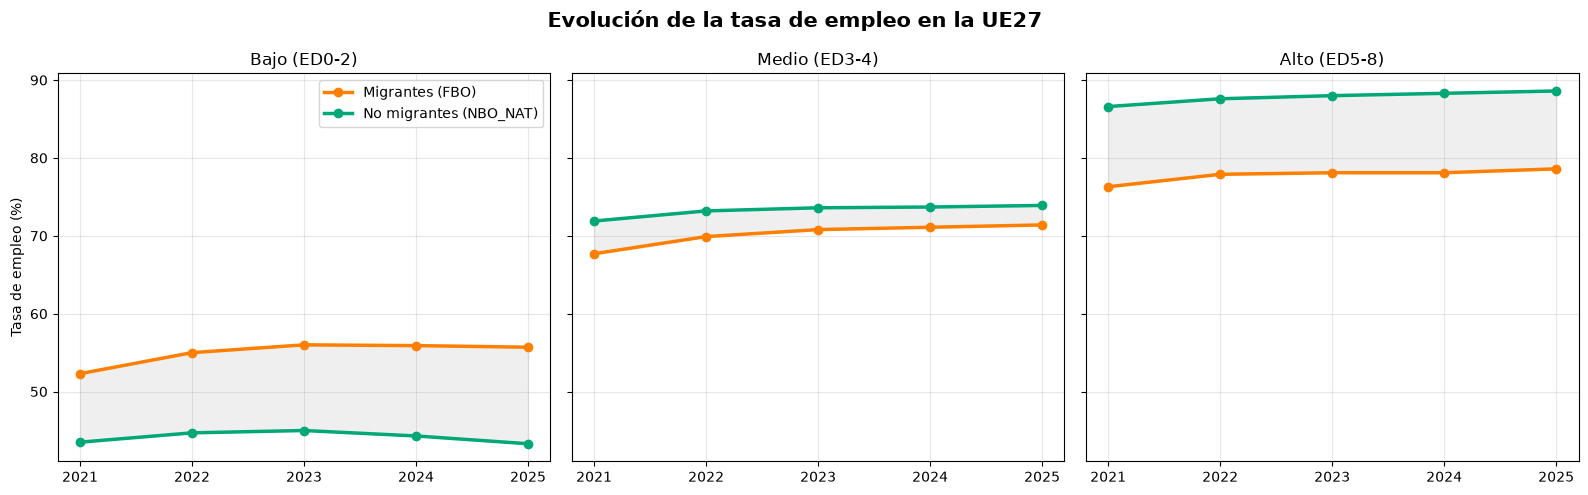

In [71]:
# Gráfico 1: Evolución de la tasa de empleo

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, lvl in zip(axes, levels):

    fbo = trend_eu[(lvl, "FBO")]
    nat = trend_eu[(lvl, "NBO_NAT")]

    ax.plot(
        years, fbo,
        marker="o",
        color=colors["FBO"],
        linewidth=2.5,
        label="Migrantes (FBO)"
    )

    ax.plot(
        years, nat,
        marker="o",
        color=colors["NBO_NAT"],
        linewidth=2.5,
        label="No migrantes (NBO_NAT)"
    )

    ax.fill_between(
        years, fbo, nat,
        color="#b0b0b0",
        alpha=0.2
    )

    ax.set_title(level_names[lvl])
    ax.set_xticks(years)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Tasa de empleo (%)")
axes[0].legend(loc="best")

fig.suptitle(
    "Evolución de la tasa de empleo en la UE27",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

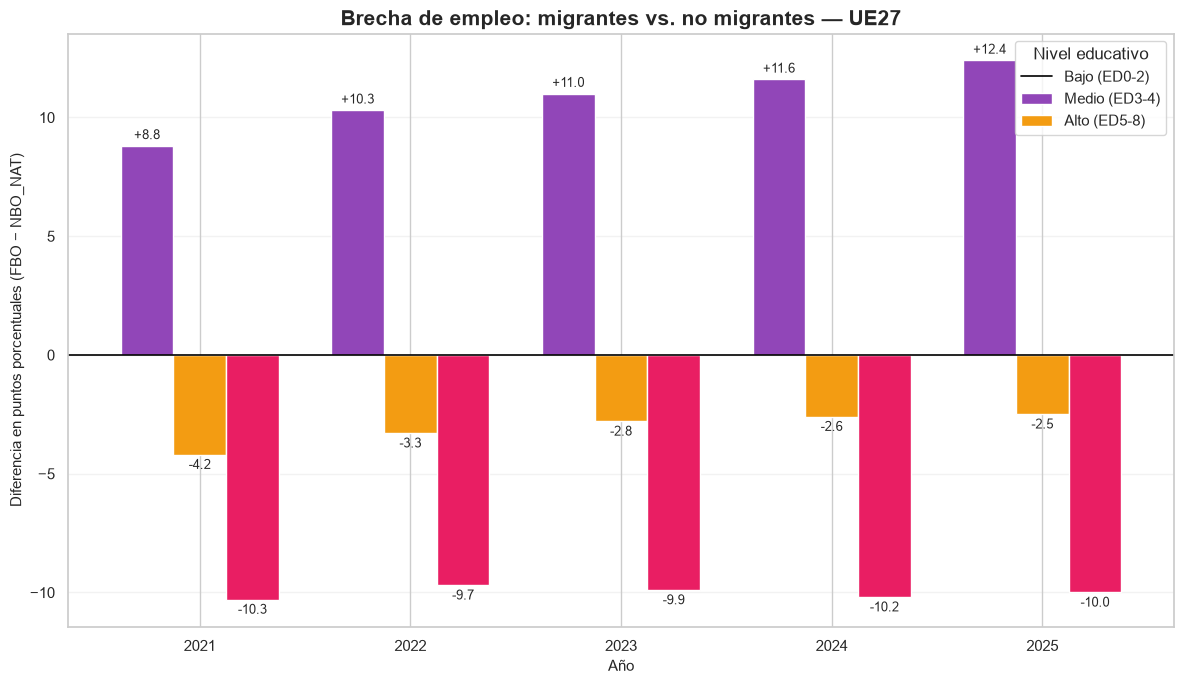

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar los datos de EU27
df_eu27 = df[
    (df["geo"] == "EU27_2020") &
    (df["citizen"] == "TOTAL") &
    (df["age"] == "Y15-64") &
    (df["sex"] == "T") &
    (df["unit"] == "PC") &
    (df["TIME_PERIOD"].isin([2021, 2022, 2023, 2024, 2025]))
].copy()

# Calcular la brecha entre migrantes y no migrantes
gap_eu27 = df_eu27.pivot_table(
    index=["TIME_PERIOD", "isced11"],
    columns="mgstatus",
    values="OBS_VALUE"
)

gap_eu27["Brecha"] = gap_eu27["FBO"] - gap_eu27["NBO_NAT"]

# Preparar los datos para el gráfico
gap = gap_eu27["Brecha"].unstack("isced11")

# Ordenar los niveles educativos
gap = gap[["ED0-2", "ED3_4", "ED5-8"]]

# Crear el gráfico
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(12, 7))

gap.plot(
    kind="bar",
    ax=ax,
    width=0.75,
    color=["#9146B8", "#F39C12", "#E91E63"]
)

# Añadir etiquetas numéricas a cada barra
for container in ax.containers:
    labels = [
        f"{bar.get_height():+.1f}"
        if pd.notna(bar.get_height())
        else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        fontsize=9,
        padding=3
    )

# Línea de referencia en cero
ax.axhline(
    y=0,
    color="black",
    linewidth=1.2
)

# Títulos y etiquetas
ax.set_title(
    "Brecha de empleo: migrantes vs. no migrantes — UE27",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Año", fontsize=11)

ax.set_ylabel(
    "Diferencia en puntos porcentuales (FBO − NBO_NAT)",
    fontsize=11
)

ax.set_xticklabels(
    gap.index.astype(int),
    rotation=0
)

ax.legend(
    title="Nivel educativo",
    labels=["Bajo (ED0-2)", "Medio (ED3-4)", "Alto (ED5-8)"]
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Что фиксируем для H2.md:
- Во всех трёх образовательных группах занятость мигрантов (FBO) постепенно растёт с 2021 по 2025 год.
- У немигрантов (NBO_NAT) с высоким уровнем образования занятость остаётся самой высокой — около 86–89%.
- У мигрантов с низким уровнем образования занятость ниже остальных групп — около 52–56%.
- В 2024–2025 годах заметна небольшая стабилизация показателей.

### Mayor tasa de empleo entre la población migrante con bajo nivel educativo

Se observa una tasa de empleo superior entre la población migrante con bajo nivel educativo (54,98%) en comparación con la población no migrante (44,16%). La diferencia es de 10,82 puntos porcentuales.

Este resultado sugiere que podrían existir diferencias en la distribución ocupacional de ambas poblaciones.

### Líneas de investigación futura

- Analizar la distribución de la población migrante por sectores de actividad.
- Investigar la presencia de trabajadores migrantes en ocupaciones que requieren trabajo físico.
- Comparar las condiciones laborales, la estabilidad del empleo y los niveles salariales.
- Examinar si esta tendencia se mantiene en España.

«La población migrante con bajo nivel educativo presenta una mayor tasa de empleo que la población no migrante, posiblemente debido a diferencias en la distribución sectorial y ocupacional».

«Entre personas con el mismo nivel educativo, la tasa de empleo es menor para la población migrante que para la población no migrante».

И ты совершенно права: мы не должны превращать этот этап в дополнительное исследование. Нам нужно визуально и аналитически ответить только на один вопрос:

¿Se cumple o no se cumple la hipótesis H2?

По нашим результатам EU27:
- Educación baja — гипотеза не подтверждается: занятость мигрантов выше.
- Educación media — гипотеза подтверждается: занятость мигрантов ниже.
- Educación alta — гипотеза подтверждается: занятость мигрантов ниже.
Следовательно, H2 se cumple parcialmente.

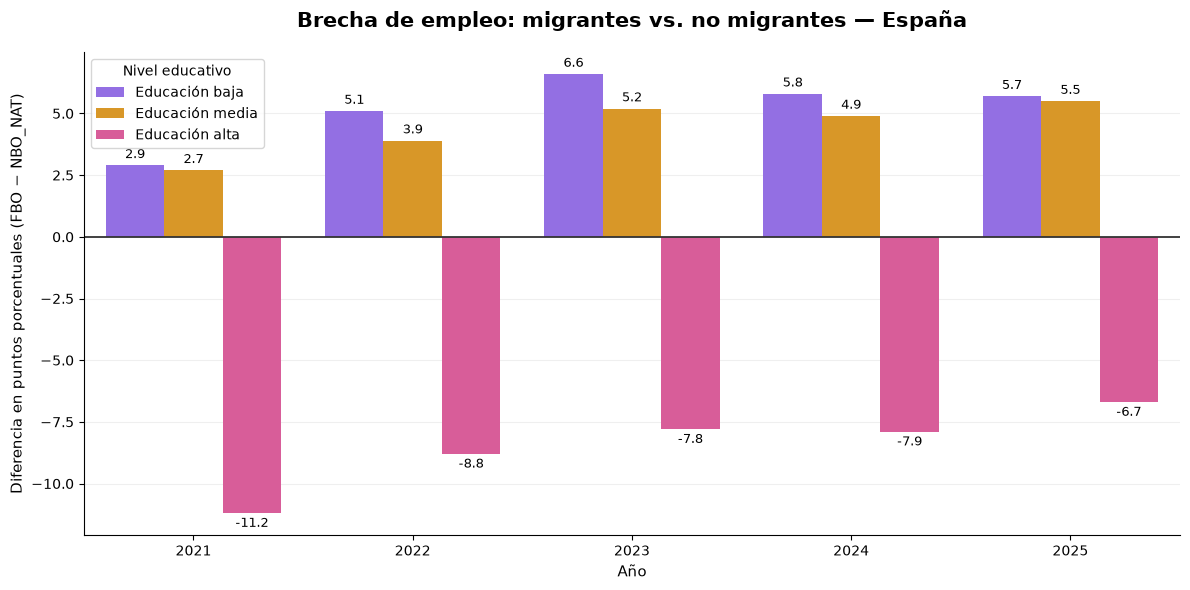

In [73]:
# Filtrar los datos de España
df_es = df[
    (df["geo"] == "ES") &
    (df["sex"] == "T") &
    (df["age"] == "Y15-64") &
    (df["citizen"] == "TOTAL")
].copy()

# Calcular la brecha de empleo por año y nivel educativo
gap_es = df_es.pivot_table(
    index=["TIME_PERIOD", "isced11"],
    columns="mgstatus",
    values="OBS_VALUE"
).reset_index()

gap_es["Brecha"] = gap_es["FBO"] - gap_es["NBO_NAT"]

# Etiquetar los niveles educativos
level_names = {
    "ED0-2": "Educación baja",
    "ED3_4": "Educación media",
    "ED5-8": "Educación alta"
}

gap_es["Nivel educativo"] = gap_es["isced11"].map(level_names)
gap_es["TIME_PERIOD"] = gap_es["TIME_PERIOD"].astype(int)

# Definir el orden de las categorías
order = [
    "Educación baja",
    "Educación media",
    "Educación alta"
]

# Paleta de colores
palette = {
    "Educación baja": "#8B5CF6",
    "Educación media": "#F59E0B",
    "Educación alta": "#EC4899"
}

# Crear gráfico
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=gap_es,
    x="TIME_PERIOD",
    y="Brecha",
    hue="Nivel educativo",
    hue_order=order,
    palette=palette,
    errorbar=None,
    ax=ax
)

# Línea de referencia
ax.axhline(0, color="#333333", linewidth=1.3)

# Añadir etiquetas de valores
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}"
        if abs(bar.get_height()) > 0.05
        else "0.0"
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        fontsize=9,
        padding=3
    )

# Estilo visual
ax.set_title(
    "Brecha de empleo: migrantes vs. no migrantes — España",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Año", fontsize=11)
ax.set_ylabel("Diferencia en puntos porcentuales (FBO − NBO_NAT)", fontsize=11)

ax.set_xticks(range(5))
ax.set_xticklabels([2021, 2022, 2023, 2024, 2025])

ax.legend(
    title="Nivel educativo",
    frameon=True,
    loc="upper left"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

sns.despine()

plt.tight_layout()
plt.show()

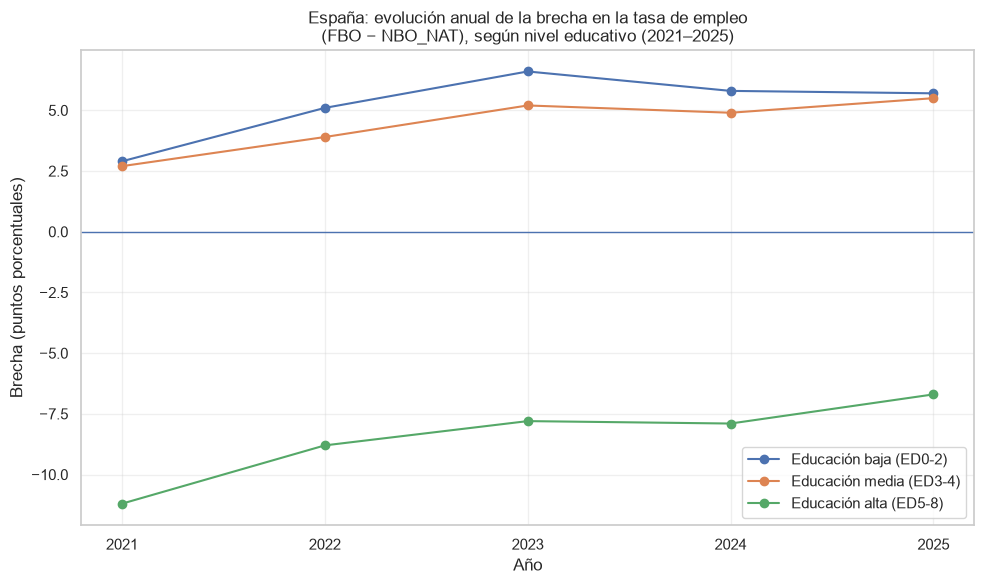

In [81]:
# Filtrar los datos de España para 2021–2025
filt = df[
    (df["geo"] == "ES") &
    (df["citizen"] == "TOTAL") &
    (df["age"] == "Y15-64") &
    (df["sex"] == "T") &
    (df["unit"] == "PC") &
    (df["TIME_PERIOD"].astype(str).isin(["2021", "2022", "2023", "2024", "2025"])) &
    (df["mgstatus"].isin(["FBO", "NBO_NAT"])) &
    (df["isced11"].isin(["ED0-2", "ED3_4", "ED5-8"]))
].copy()

# Calcular la brecha entre población migrante y no migrante
tabla = filt.pivot_table(
    index=["TIME_PERIOD", "isced11"],
    columns="mgstatus",
    values="OBS_VALUE"
).reset_index()

tabla["brecha"] = tabla["FBO"] - tabla["NBO_NAT"]

# Representar la evolución de la brecha
niveles = {
    "ED0-2": "Educación baja (ED0-2)",
    "ED3_4": "Educación media (ED3-4)",
    "ED5-8": "Educación alta (ED5-8)"
}

plt.figure(figsize=(10, 6))

for nivel, etiqueta in niveles.items():
    sub = tabla[tabla["isced11"] == nivel].sort_values("TIME_PERIOD")
    plt.plot(sub["TIME_PERIOD"], sub["brecha"], marker="o", label=etiqueta)

plt.axhline(0, linewidth=1)
plt.title("España: evolución anual de la brecha en la tasa de empleo\n(FBO − NBO_NAT), según nivel educativo (2021–2025)")
plt.xlabel("Año")
plt.ylabel("Brecha (puntos porcentuales)")
plt.xticks([2021, 2022, 2023, 2024, 2025])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [78]:
# Calcular la brecha anual entre migrantes y no migrantes
brecha_paises = df_paises.pivot_table(
    index=["geo", "TIME_PERIOD", "isced11"],
    columns="mgstatus",
    values="OBS_VALUE"
)

# Calcular la diferencia en puntos porcentuales
brecha_paises["Brecha"] = (
    brecha_paises["FBO"] - brecha_paises["NBO_NAT"]
)

# Calcular la media de las tasas anuales por país y nivel educativo
promedio_paises = (
    brecha_paises
    .groupby(["geo", "isced11"])
    .agg(
        FBO=("FBO", "mean"),
        NBO_NAT=("NBO_NAT", "mean"),
        Brecha_media=("Brecha", "mean"),
        Años_disponibles=("Brecha", "count")
    )
    .reset_index()
)

# Seleccionar países interesantes
paises_interesantes = ["NL", "DE", "PT", "CY"]

# Filtrar los países seleccionados
tabla_interesante = promedio_paises[
    promedio_paises["geo"].isin(paises_interesantes)
].copy()

# Mantener solamente los casos con datos completos para los cinco años
tabla_interesante = tabla_interesante[
    tabla_interesante["Años_disponibles"] == 5
]

# Ordenar los resultados
tabla_interesante = tabla_interesante.sort_values(
    ["geo", "isced11"]
)

# Redondear los valores
tabla_interesante[
    ["FBO", "NBO_NAT", "Brecha_media"]
] = tabla_interesante[
    ["FBO", "NBO_NAT", "Brecha_media"]
].round(2)

# Mostrar la tabla
tabla_interesante[
    ["geo", "isced11", "FBO", "NBO_NAT", "Brecha_media"]
]

,geo,isced11,FBO,NBO_NAT,Brecha_media
15,CY,ED0-2,70.02,44.50,25.52
16,CY,ED3_4,76.76,73.28,3.48
17,CY,ED5-8,77.48,88.78,-11.30
21,DE,ED0-2,57.48,50.10,7.38
22,DE,ED3_4,76.82,82.72,-5.90
23,DE,ED5-8,77.58,91.46,-13.88
72,NL,ED0-2,57.96,72.88,-14.92
73,NL,ED3_4,72.42,85.40,-12.98
74,NL,ED5-8,81.00,91.16,-10.16
81,PT,ED0-2,65.38,61.84,3.54


In [80]:
import pandas as pd
import numpy as np

# Seleccionar los países para comprobar la estabilidad
paises_estabilidad = ["CY", "DE", "NL", "PT"]

# Convertir el índice en columnas
datos_estabilidad = brecha_paises.reset_index()

# Filtrar los países seleccionados
datos_estabilidad = datos_estabilidad[
    datos_estabilidad["geo"].isin(paises_estabilidad)
].copy()

# Agrupar los datos por país y nivel educativo
estabilidad = (
    datos_estabilidad
    .groupby(["geo", "isced11"])
    .agg(
        Brecha_media=("Brecha", "mean"),
        Brecha_min=("Brecha", "min"),
        Brecha_max=("Brecha", "max"),
        Años_disponibles=("Brecha", "count"),
        Direcciones_diferentes=(
            "Brecha",
            lambda x: np.sign(x.dropna()).nunique()
        )
    )
    .reset_index()
)

# Comprobar si la dirección de la brecha se mantiene estable
estabilidad["Dirección_estable"] = (
    estabilidad["Direcciones_diferentes"] == 1
)

# Redondear los valores
estabilidad[
    ["Brecha_media", "Brecha_min", "Brecha_max"]
] = estabilidad[
    ["Brecha_media", "Brecha_min", "Brecha_max"]
].round(2)

# Ordenar los resultados
estabilidad = estabilidad.sort_values(
    ["geo", "isced11"]
)

# Mostrar la tabla final
estabilidad[
    [
        "geo",
        "isced11",
        "Brecha_media",
        "Brecha_min",
        "Brecha_max",
        "Años_disponibles",
        "Dirección_estable"
    ]
]

,geo,isced11,Brecha_media,Brecha_min,Brecha_max,Años_disponibles,Dirección_estable
0,CY,ED0-2,25.52,23.7,30.1,5,True
1,CY,ED3_4,3.48,2.9,4.1,5,True
2,CY,ED5-8,-11.30,-12.2,-9.6,5,True
3,DE,ED0-2,7.38,5.4,10.8,5,True
4,DE,ED3_4,-5.90,-6.2,-5.6,5,True
5,DE,ED5-8,-13.88,-15.1,-12.4,5,True
6,NL,ED0-2,-14.92,-16.9,-13.3,5,True
7,NL,ED3_4,-12.98,-14.7,-11.7,5,True
8,NL,ED5-8,-10.16,-12.2,-8.9,5,True
9,PT,ED0-2,3.54,2.0,5.4,5,True


Hipótesis parcialmente respaldada

Los resultados del análisis descriptivo respaldan la hipótesis H2: la diferencia en la tasa de empleo entre la población migrante y no migrante varía según el nivel educativo y el país. En el agregado EU27, la brecha media (FBO − NBO_NAT) es de +10,82 puntos porcentuales para educación baja, −3,08 p.p. para educación media y −10,02 p.p. para educación alta. En España, las brechas son +5,22 p.p., +4,44 p.p. y −8,48 p.p., respectivamente.

El análisis de países seleccionados confirma la heterogeneidad del patrón: por ejemplo, Países Bajos presenta brechas negativas en los tres niveles educativos, mientras que en Alemania, Chipre y Portugal la dirección cambia según el nivel educativo. En los 12 casos país–nivel educativo examinados, la dirección de la brecha se mantuvo durante 2021–2025.

Estos resultados son descriptivos y no permiten establecer causalidad ni significancia estadística. Las brechas medias corresponden a promedios simples de tasas anuales, no ponderados por población. Además, EU27 incluye España.